# 07 · Ensamble, intervalos calibrados, preguntas guía y predicciones finales — Reto AgroCebada 2026

## Punto de partida (resultados del cuaderno 06)
- **La ubicación explica casi todo lo que se puede predecir.** La media municipal obtiene un RMSE de 0.498 t/ha; el mejor modelo, nuestro proceso gaussiano jerárquico (efecto de municipio + vecinas a escala de finca), obtiene 0.494: mejor, pero dentro del ruido entre pliegues.
- **Dentro de un municipio, ninguna variable satelital, climática o de suelo muestra una señal distinguible del azar** con 138 parcelas. Este cuaderno lo pone a prueba formalmente con una prueba de permutación.
- **¿Pueden los datos satelitales sustituir a la ubicación en zonas sin historial de rendimiento?** Este cuaderno lo evalúa con modelos que no reciben ninguna información de ubicación.

## Qué construye este cuaderno
1. **El modelo**: el mejor predictor para las 59 parcelas, elegido por los datos. Se prueba un ensamble apilado cuyos pesos se ajustan con predicciones fuera de pliegue y se validan en parcelas apartadas. Candidatos: media municipal, PG jerárquico, PG jerárquico + variables y dos modelos **solo satelitales** (sin ninguna información de ubicación). Si los modelos satelitales mejoran el ensamble reciben peso; si no, no.
2. **El modelo satelital sin ubicación**, evaluado con honestidad, que sirve para responder las preguntas guía y medir qué tanto se transfiere a zonas nuevas.

## Pasos
| Paso | Qué |
|---|---|
| A | Modelos solo satelitales (sin municipio ni coordenadas): ¿cuánto de la «ubicación» puede reemplazar la percepción remota? |
| B | Ensamble apilado: pesos por mínimos cuadrados no negativos sobre predicciones fuera de pliegue, validados en mitades apartadas |
| C | Intervalos de predicción calibrados (predicción conforme), «rendimiento financiable» (P20) y niveles de riesgo |
| D | Preguntas guía: (1) índice más importante, (2) variable climática de mayor peso, (3) mejor combinación de variables |
| E | Ajuste final con las 138 parcelas → predicciones de las 59 parcelas; exportación para la entrega y la aplicación |

## Salidas
| Archivo | Contenido |
|---|---|
| `outputs/predicciones_finales.csv` | las 59 parcelas de predicción: rendimiento predicho, P10/P20/P80/P90, nivel de riesgo y predicción solo satelital |
| `outputs/predicciones_todas.csv` | las 197 parcelas (en las de entrenamiento, predicciones fuera de pliegue), para la aplicación |
| `outputs/app_bundle/` | parámetros del modelo, datos de entrenamiento necesarios para volver a correrlo y tablas de las preguntas guía |
| `qa/figures/nb07_*`, `qa/nb07_report.md` | verificaciones, figuras y reporte |

**Tiempo de ejecución:** ~10–15 minutos.

## 0 · Preparación

In [1]:
# 0.1 · Librerías, Drive y rutas
import os, sys, json, time, warnings, itertools
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.optimize import nnls
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold

warnings.filterwarnings("ignore")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

BASE = Path("/content/drive/MyDrive/AgroCebada") if IN_COLAB else Path(os.environ.get("AGC_BASE", "AgroCebada"))
FEATURES, MODELS, QA, SRC, OUT = BASE / "features", BASE / "models", BASE / "qa", BASE / "src", BASE / "outputs"
FIG, APP = QA / "figures", OUT / "app_bundle"
for d in [FIG, OUT, APP]:
    d.mkdir(parents=True, exist_ok=True)
for f in [FEATURES / "master.parquet", MODELS / "oof_nb06.parquet", SRC / "agc_models.py"]:
    assert f.exists(), f"Falta {f}: ejecuta primero los cuadernos 05 y 06."
sys.path.insert(0, str(SRC))
import importlib, agc_models
importlib.reload(agc_models)
from agc_models import select_features, prep, muni_prior, HierGP
SEED = 42
RNG = np.random.default_rng(SEED)
if "display" not in globals():
    display = print
print(f"BASE = {BASE} | Colab: {IN_COLAB}")

Mounted at /content/drive
BASE = /content/drive/MyDrive/AgroCebada | Colab: True


In [2]:
# 0.2 · Configuración
FINAL_CHOICE = "auto"        # "auto" = deciden los datos (apilamiento); o forzar "5 hierarchical GP" / "6 hierarchical GP + features"
N_REP_IMPORTANCE = 3         # repeticiones usadas para la capacidad individual y la ablación por familias (15 pliegues)
N_PERM_TEST = 1000           # permutaciones para la prueba de señal dentro de municipio
N_STACK_SPLITS = 200         # particiones aleatorias por mitades para validar los pesos del ensamble
LEVELS = {"P10": 0.10, "P20": 0.20, "P80": 0.80, "P90": 0.90}
K_GRID = [5, 10, 20, 40]

COLORS = {"location": "#2a78d6", "satellite": "#eb6834", "ensemble": "#1c5cab", "baseline": "#9a9a94"}
TIER_COLORS = {"Bajo": "#1baf7a", "Medio": "#eda100", "Alto": "#e34948"}
GREY, RED, INK = "#9a9a94", "#e34948", "#2b2b28"
# nombres en español para las figuras (los identificadores internos no cambian)
NOMBRES = {"0 municipality mean": "0 media municipal", "5 hierarchical GP": "5 PG jerárquico",
           "6 hierarchical GP + features": "6 PG jerárquico + variables", "8 satellite-only ridge": "8 ridge solo satelital",
           "9 satellite-only random forest": "9 bosque aleatorio solo satelital"}
VAR_CLIMA = {"prec": "precipitación", "tmax": "temperatura máxima", "tmin": "temperatura mínima", "tmean": "temperatura media",
             "amp": "amplitud térmica", "pet": "evapotranspiración potencial", "wb": "balance hídrico", "gdd": "grados-día"}
FAMILIAS = {"phenology": "fenología", "satellite indices": "índices satelitales", "history 2022–24": "historial 2022–24",
            "climate": "clima", "terrain": "terreno", "soil": "suelo"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#b8b7ae", "axes.labelcolor": INK, "xtick.color": "#6b6b66",
                     "ytick.color": "#6b6b66", "font.size": 9, "legend.frameon": False})
CHECKS = []
def check(name, ok, detail="", warn_only=True, info=False):
    status = "INFO" if info else ("PASS" if ok else ("WARN" if warn_only else "FAIL"))
    rec = {"check": name, "status": status, "detail": str(detail)}
    for j, r in enumerate(CHECKS):
        if r["check"] == name:
            CHECKS[j] = rec
            break
    else:
        CHECKS.append(rec)
    print(f"[{status}] {name}" + (f" — {detail}" if detail != "" else ""))

In [3]:
# 0.3 · Carga de datos
MASTER = pd.read_parquet(FEATURES / "master.parquet").set_index("ID_POLIGONO")
MASTER["x_km"], MASTER["y_km"] = MASTER.x_m / 1000, MASTER.y_m / 1000
cat = pd.read_csv(FEATURES / "feature_catalog_all.csv", index_col=0)
cat.index.name = "feature"
CANDS = [c for c in cat.index[cat.use_in_model.astype(bool)] if c in MASTER and MASTER[c].nunique() > 2]
CLUSTERS = cat.redundancy_cluster.dropna().astype(int).to_dict()
Y, XY = "RENDIMIENTO_T_HA", ["x_km", "y_km"]
TR = MASTER[MASTER.is_train.astype(bool)].copy()
PR = MASTER[~MASTER.is_train.astype(bool)].copy()
OOF6 = pd.read_parquet(MODELS / "oof_nb06.parquet")
OOF6 = OOF6[OOF6.scheme == "main"]
REPEATS = sorted(OOF6.repeat.unique())
FOLDS = [f for f in json.loads((MODELS / "cv_folds.json").read_text())["folds"] if f["repeat"] in REPEATS]
SPATIAL = json.loads((MODELS / "cv_spatial.json").read_text())["folds"]
print(f"{len(TR)} parcelas de entrenamiento / {len(PR)} de predicción · {len(CANDS)} variables · repeticiones en las predicciones del cuaderno 06: {len(REPEATS)}")

138 parcelas de entrenamiento / 59 de predicción · 264 variables · repeticiones en las predicciones del cuaderno 06: 10


## 1 · Paso A: modelos solo satelitales. ¿Cuánto de la «ubicación» puede reemplazar la percepción remota?

Estos modelos **no reciben municipio ni coordenadas**: solo variables satelitales, climáticas, de terreno y de suelo, como sería el caso de una parcela en un municipio sin registros de rendimiento. Dos algoritmos:
- **ridge** con selección de variables dentro del pliegue (número de variables por validación cruzada interna, una por grupo de redundancia; el orden se basa en la |ρ| *global* porque no hay municipio sobre el cual centrar);
- **bosque aleatorio** con todas las variables candidatas (500 árboles, hojas de al menos 3 parcelas).

Se evalúan en los mismos pliegues fijos que todos los demás modelos y en los bloques espaciales (zonas apartadas), donde los modelos de ubicación no tienen información local.

In [4]:
# 1.1 · Modelos solo satelitales en los pliegues fijos
from numpy.linalg import LinAlgError
from sklearn.linear_model import Ridge

def safe_prep(tr, te, cols):
    """prep() con protección: valores no finitos → 0 y valores estandarizados recortados a ±10."""
    A, B = prep(tr, te, cols)
    clean = lambda M: np.clip(np.nan_to_num(M, nan=0.0, posinf=0.0, neginf=0.0), -10, 10)
    return clean(A), clean(B)

def fit_ridge(A, yv_, alphas):
    """RidgeCV por descomposición en valores propios (estable con columnas colineales); si falla, SVD y luego ridge con alfa fijo."""
    for mode in ("eigen", "svd"):
        try:
            return RidgeCV(alphas=alphas, gcv_mode=mode).fit(A, yv_)
        except (LinAlgError, ValueError):
            continue
    return Ridge(alpha=float(np.median(alphas))).fit(A, yv_)

def select_overall(tr, k):
    X = tr[CANDS].astype(float)
    X = X.fillna(X.median())
    rho = X.corrwith(tr[Y], method="spearman").abs().fillna(0).sort_values(ascending=False)
    chosen, used = [], set()
    for f in rho.index:
        c = CLUSTERS.get(f, f)
        if c in used:
            continue
        chosen.append(f); used.add(c)
        if len(chosen) == k:
            break
    return chosen

def sat_ridge(tr, te):
    def fit_pred(a, b, k):
        cols = select_overall(a, k)
        A, B = safe_prep(a, b, cols)
        return fit_ridge(A, a[Y], np.logspace(-1, 4, 30)).predict(B)
    inner = KFold(5, shuffle=True, random_state=SEED)
    sc = {k: [] for k in K_GRID}
    for ia, ib in inner.split(tr):
        for k in K_GRID:
            sc[k].append(np.mean((tr[Y].iloc[ib].to_numpy() - fit_pred(tr.iloc[ia], tr.iloc[ib], k)) ** 2))
    k = min(sc, key=lambda k: np.mean(sc[k]))
    return fit_pred(tr, te, k)

def sat_rf(tr, te):
    A, B = safe_prep(tr, te, CANDS)
    return RandomForestRegressor(500, min_samples_leaf=3, max_features=0.33, random_state=SEED, n_jobs=-1).fit(A, tr[Y]).predict(B)

def run_sat(fold_list, scheme):
    rows = []
    tr_ids = TR.index.to_numpy()
    for name, fn in [("8 satellite-only ridge", sat_ridge), ("9 satellite-only random forest", sat_rf)]:
        t0 = time.time()
        for f in fold_list:
            te = np.array(f["test"]); trn = TR.loc[np.setdiff1d(tr_ids, te)]; tst = TR.loc[te]
            rows.append(pd.DataFrame({"scheme": scheme, "model": name, "repeat": f.get("repeat", 0), "fold": f["fold"],
                                      "ID_POLIGONO": te, "y": tst[Y].to_numpy(), "pred": fn(trn, tst), "sd": np.nan}))
        print(f"  {scheme:8s} {name:32s} {time.time() - t0:6.1f} s")
    return pd.concat(rows, ignore_index=True)

OOF_SAT = run_sat(FOLDS, "main")
OOF_SAT_SP = run_sat(SPATIAL, "spatial")

def score(oof):
    g = oof.groupby(["model", "repeat"])
    r = g.apply(lambda x: pd.Series({"rmse": np.sqrt(np.mean((x.y - x.pred) ** 2)), "mae": np.mean(np.abs(x.y - x.pred)),
                                     "r2": 1 - ((x.y - x.pred) ** 2).sum() / ((x.y - x.y.mean()) ** 2).sum()}))
    return r.groupby("model").mean()

OOF6_SP = pd.read_parquet(MODELS / "oof_nb06.parquet").query("scheme == 'spatial'")
ALL_MAIN = pd.concat([OOF6, OOF_SAT], ignore_index=True)
gm = TR[Y].mean()
SCORES = score(ALL_MAIN)
SCORES_SP = score(pd.concat([OOF6_SP, OOF_SAT_SP], ignore_index=True))
show = ["0 municipality mean", "5 hierarchical GP", "8 satellite-only ridge", "9 satellite-only random forest"]
display(pd.concat({"principal (pliegues aleatorios)": SCORES.loc[show], "bloques espaciales (zonas nuevas)": SCORES_SP.loc[show]}, axis=1).round(3))
best_sat = SCORES.loc[["8 satellite-only ridge", "9 satellite-only random forest"], "rmse"].idxmin()
var_tot = TR[Y].var(ddof=0)
check("Modelo solo satelital frente a no saber nada (RMSE de la media general ≈ DE del rendimiento)", SCORES.loc[best_sat, "rmse"] < np.sqrt(var_tot),
      f"{best_sat}: RMSE {SCORES.loc[best_sat, 'rmse']:.3f} frente a {np.sqrt(var_tot):.3f}; R² {SCORES.loc[best_sat, 'r2']:.3f} "
      f"(ubicación: R² {SCORES.loc['0 municipality mean', 'r2']:.3f})", info=True)
sp_gain = SCORES_SP.loc[best_sat, "rmse"] - SCORES_SP.loc["0 municipality mean", "rmse"]
check("En zonas NUEVAS (bloques espaciales), solo satelital frente a media municipal", sp_gain < 0,
      f"{best_sat} {SCORES_SP.loc[best_sat, 'rmse']:.3f} frente a media municipal {SCORES_SP.loc['0 municipality mean', 'rmse']:.3f} t/ha (Δ {sp_gain:+.3f})", info=True)

  main     8 satellite-only ridge            334.8 s
  main     9 satellite-only random forest    125.4 s
  spatial  8 satellite-only ridge             37.1 s
  spatial  9 satellite-only random forest     13.2 s
                               principal (pliegues aleatorios)               bloques espaciales (zonas nuevas)              
                                                          rmse    mae     r2                              rmse    mae     r2
model                                                                                                                       
0 municipality mean                                      0.509  0.331  0.640                             0.657  0.455  0.400
5 hierarchical GP                                        0.503  0.347  0.649                             0.659  0.465  0.397
8 satellite-only ridge                                   0.575  0.430  0.539                             0.748  0.593  0.221
9 satellite-only random forest        

## 2 · Paso B: el ensamble apilado. Los datos deciden los pesos

**Apilamiento.** Cada modelo candidato tiene una predicción fuera de pliegue para cada parcela de entrenamiento (hecha sin ver esa parcela). Buscamos pesos no negativos *w* (que suman 1) tales que el promedio ponderado de los candidatos quede lo más cerca posible de los rendimientos observados: mínimos cuadrados no negativos (NNLS). Un modelo que no aporta nada recibe peso 0.

**Validación de los pesos.** Ajustar los pesos y evaluarlos en las mismas parcelas favorecería al ensamble. Por eso dividimos al azar las parcelas de entrenamiento en dos mitades, ajustamos los pesos en una y evaluamos en la otra, 21 veces por cada una de las 10 repeticiones de los pliegues (210 particiones). El ensamble solo se adopta si supera al mejor modelo individual en las mitades apartadas por más de un error estándar.

                                weight (all OOF)  median weight (half splits)  share of splits with weight > 0.05
0 municipality mean                        0.270                         0.29                               0.629
5 hierarchical GP                          0.578                         0.47                               0.724
6 hierarchical GP + features               0.000                         0.00                               0.124
8 satellite-only ridge                     0.016                         0.00                               0.376
9 satellite-only random forest             0.136                         0.04                               0.481
[WARN] Ensamble apilado frente al mejor modelo individual en mitades apartadas — mejor individual: 5 hierarchical GP; Δ RMSE del ensamble +0.0096 ± 0.0011 → sin ganancia: se conserva el mejor modelo individual
[INFO] Peso que los datos asignan a los modelos solo satelitales — 15.2 % del ensamble
[INFO] Modelo final

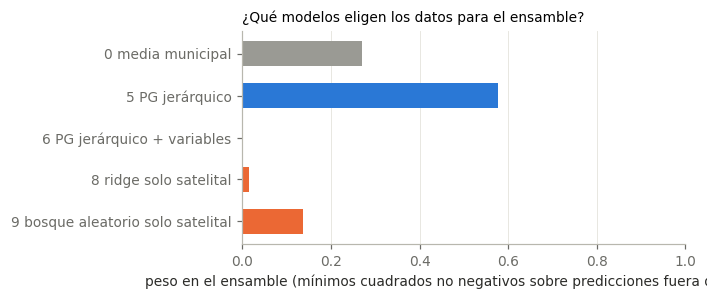

In [5]:
# 2.1 · Apilamiento con validación en mitades apartadas
CANDIDATES = ["0 municipality mean", "5 hierarchical GP", "6 hierarchical GP + features", "8 satellite-only ridge", "9 satellite-only random forest"]
P = ALL_MAIN[ALL_MAIN.model.isin(CANDIDATES)].pivot_table(index=["repeat", "ID_POLIGONO"], columns="model", values="pred")[CANDIDATES]
yv = TR.loc[P.index.get_level_values(1), Y].to_numpy()
best_single = SCORES.loc[CANDIDATES, "rmse"].idxmin()

def nnls_w(Pm, yy):
    w, _ = nnls(Pm, yy)
    return w / w.sum() if w.sum() > 0 else np.ones(Pm.shape[1]) / Pm.shape[1]

diffs, weights = [], []
for r in REPEATS:
    m = P.index.get_level_values(0) == r
    Pr, yr = P[m].to_numpy(), yv[m]
    bi = CANDIDATES.index(best_single)
    for _ in range(N_STACK_SPLITS // len(REPEATS) + 1):
        idx = RNG.permutation(len(yr)); a, b = idx[: len(yr) // 2], idx[len(yr) // 2:]
        w = nnls_w(Pr[a], yr[a])
        weights.append(w)
        diffs.append(np.sqrt(np.mean((yr[b] - Pr[b] @ w) ** 2)) - np.sqrt(np.mean((yr[b] - Pr[b, bi]) ** 2)))
diffs, W = np.array(diffs), np.array(weights)
d_mean, d_se = diffs.mean(), diffs.std(ddof=1) / np.sqrt(len(diffs))
W_FULL = nnls_w(P.to_numpy(), yv)
wt = pd.DataFrame({"weight (all OOF)": W_FULL, "median weight (half splits)": np.median(W, 0),
                   "share of splits with weight > 0.05": (W > 0.05).mean(0)}, index=CANDIDATES)
display(wt.round(3))
use_stack = d_mean < -d_se
check("Ensamble apilado frente al mejor modelo individual en mitades apartadas", use_stack,
      f"mejor individual: {best_single}; Δ RMSE del ensamble {d_mean:+.4f} ± {d_se:.4f} → " + ("se adopta el ensamble" if use_stack else "sin ganancia: se conserva el mejor modelo individual"))
sat_w = W_FULL[[CANDIDATES.index("8 satellite-only ridge"), CANDIDATES.index("9 satellite-only random forest")]].sum()
check("Peso que los datos asignan a los modelos solo satelitales", True, f"{100 * sat_w:.1f} % del ensamble", info=True)

if FINAL_CHOICE == "auto":
    FINAL = "stack" if use_stack else best_single
else:
    FINAL = FINAL_CHOICE
check("Modelo final del reto", True, FINAL + (f" (forzado por FINAL_CHOICE)" if FINAL_CHOICE != "auto" else " (elegido por los datos)"), info=True)

fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.barh([NOMBRES.get(m, m) for m in wt.index[::-1]], wt["weight (all OOF)"][::-1],
        color=[COLORS["satellite"] if "satellite" in c else (COLORS["baseline"] if c.startswith("0") else COLORS["location"]) for c in wt.index[::-1]], height=0.6)
ax.set_xlim(0, 1); ax.grid(axis="y", visible=False)
ax.set_xlabel("peso en el ensamble (mínimos cuadrados no negativos sobre predicciones fuera de pliegue)")
ax.set_title("¿Qué modelos eligen los datos para el ensamble?", loc="left", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "nb07_stack_weights.png", bbox_inches="tight"); plt.show()

In [6]:
# 2.2 · Predicciones fuera de pliegue e incertidumbre del modelo final
if FINAL == "stack":
    oof_final = pd.DataFrame({"repeat": P.index.get_level_values(0), "ID_POLIGONO": P.index.get_level_values(1),
                              "pred": P.to_numpy() @ W_FULL, "y": yv})
    sd_src = ALL_MAIN[ALL_MAIN.model == "5 hierarchical GP"][["repeat", "ID_POLIGONO", "sd"]]
    oof_final = oof_final.merge(sd_src, on=["repeat", "ID_POLIGONO"])
else:
    oof_final = ALL_MAIN[ALL_MAIN.model == FINAL][["repeat", "ID_POLIGONO", "pred", "y", "sd"]].copy()
    if oof_final.sd.isna().all():
        oof_final = oof_final.drop(columns="sd").merge(ALL_MAIN[ALL_MAIN.model == "5 hierarchical GP"][["repeat", "ID_POLIGONO", "sd"]], on=["repeat", "ID_POLIGONO"])
rm = oof_final.groupby("repeat").apply(lambda x: np.sqrt(np.mean((x.y - x.pred) ** 2))).mean()
print(f"RMSE fuera de pliegue del modelo final: {rm:.4f} t/ha")

RMSE fuera de pliegue del modelo final: 0.5027 t/ha


## 3 · Paso C: intervalos calibrados, «rendimiento financiable» y niveles de riesgo

**Por qué calibrar.** La incertidumbre que reporta un modelo puede ser demasiado estrecha o demasiado amplia. La *predicción conforme* lo corrige con los errores fuera de pliegue: para cada parcela de entrenamiento calculamos el error estandarizado *s* = (observado − predicho) / σ, donde σ es la desviación estándar predictiva del PG jerárquico (mayor en parcelas sin vecinas cercanas). Los cuantiles empíricos de *s* dan los multiplicadores de los límites:

$$P_q = \hat y + s_q\,\sigma, \qquad q \in \{0.10, 0.20, 0.80, 0.90\}$$

No requiere suponer normalidad; solo supone que las 59 parcelas de predicción se comportan como las de entrenamiento, lo que respalda la comparación de distancias del cuaderno 05.

**Validación.** Calculamos los cuantiles con la mitad de las parcelas de entrenamiento y medimos la cobertura en la otra mitad, 200 veces.

**Para decisiones de crédito:**
- **P20 = «rendimiento financiable»**: un rendimiento que la parcela debería superar 4 de cada 5 veces. Usar P20 en lugar de la predicción puntual para dimensionar el crédito protege contra la sobrestimación sin sesgar las predicciones evaluadas.
- **Nivel de riesgo**: a partir de la caída relativa (predicho − P20) / predicho: *Bajo* (tercio inferior de las 59 parcelas), *Medio* y *Alto* (tercio superior). Las parcelas lejanas a cualquier parcela de entrenamiento o en municipios con pocos registros reciben intervalos más amplios y niveles más altos.

In [7]:
# 3.1 · Cuantiles conformes y su validación
s = ((oof_final.y - oof_final.pred) / oof_final.sd).to_numpy()
Q = {k: float(np.quantile(s, q)) for k, q in LEVELS.items()}
display(pd.Series(Q, name="standardised quantile").round(3).to_frame().T)
cov = {"P20–P90 (70 %)": [], "P10–P90 (80 %)": [], "above P20 (80 %)": []}
ids = oof_final.ID_POLIGONO.unique()
for _ in range(200):
    half = set(RNG.choice(ids, len(ids) // 2, replace=False))
    a = oof_final.ID_POLIGONO.isin(half).to_numpy()
    q = {k: np.quantile(s[a], v) for k, v in LEVELS.items()}
    sb = s[~a]
    cov["P10–P90 (80 %)"].append(np.mean((sb >= q["P10"]) & (sb <= q["P90"])))
    cov["P20–P90 (70 %)"].append(np.mean((sb >= q["P20"]) & (sb <= q["P90"])))
    cov["above P20 (80 %)"].append(np.mean(sb >= q["P20"]))
cov_tab = pd.DataFrame({k: [np.mean(v), np.std(v)] for k, v in cov.items()}, index=["mean coverage", "sd"]).T
display(cov_tab.round(3))
check("Los intervalos conformes mantienen su cobertura nominal en parcelas apartadas (±5 puntos)",
      abs(cov_tab.loc["P10–P90 (80 %)", "mean coverage"] - 0.80) <= 0.05 and abs(cov_tab.loc["above P20 (80 %)", "mean coverage"] - 0.80) <= 0.05,
      f"P10–P90: {100 * cov_tab.loc['P10–P90 (80 %)', 'mean coverage']:.1f} % (meta 80); por encima de P20: {100 * cov_tab.loc['above P20 (80 %)', 'mean coverage']:.1f} % (meta 80)")

                         P10    P20    P80    P90
standardised quantile -1.152 -0.805  0.766  1.128
                  mean coverage     sd
P20–P90 (70 %)            0.693  0.068
P10–P90 (80 %)            0.791  0.061
above P20 (80 %)          0.795  0.060
[PASS] Los intervalos conformes mantienen su cobertura nominal en parcelas apartadas (±5 puntos) — P10–P90: 79.1 % (meta 80); por encima de P20: 79.5 % (meta 80)


## 4 · Paso D: las preguntas guía

Las bases otorgan puntos por responder: **(1) qué índice es el más importante, (2) qué variable climática tiene mayor peso y (3) qué combinación de variables funciona mejor.** Respondemos con dos enfoques complementarios, porque la respuesta honesta depende de lo que ya se sabe de la parcela:

**Enfoque 1: cuando se conoce el municipio (la situación del reto).** ¿Alguna variable añade información *más allá de la ubicación*? Comparamos la correlación más fuerte dentro de municipio contra una **prueba de permutación**: los rendimientos se barajan *dentro* de cada municipio 1,000 veces (lo que destruye cualquier relación real entre variable y rendimiento pero conserva la ubicación) y registramos la correlación más fuerte que produce el azar. Si la real no supera al azar, con 138 parcelas no se puede afirmar que alguna variable aporte señal más allá de la ubicación.

**Enfoque 2: cuando no se conoce el municipio (escalar a zonas nuevas).** ¿Qué variables *reemplazan* mejor a la ubicación?
- **P1 y P2, capacidad predictiva individual:** para cada índice satelital (todas sus ventanas y estadísticos, por ejemplo todas las variables de NDVI) y cada variable climática (todas sus ventanas y anomalías) se entrena un modelo ridge **solo con ese grupo** y se evalúa en los pliegues fijos. El índice cuyas variables predicen mejor por sí solas es el más importante. *¿Por qué no la importancia por permutación dentro de un modelo grande?* La probamos: con ~260 variables muy correlacionadas, barajar un grupo casi no cambia el modelo porque otros grupos lo sustituyen, y las importancias salen cercanas a cero o negativas, sin información útil. La capacidad individual responde directamente la pregunta práctica: *si FIRA solo pudiera monitorear un índice, ¿cuál sería?*
- **P3, ablación por familias:** modelos ridge entrenados con cada combinación de las seis familias de variables (63 combinaciones), evaluados en los mismos pliegues.

In [8]:
# 4.1 · Enfoque 1: prueba de permutación de la señal dentro de municipio
Xr = TR[CANDS].astype(float)
Xr = Xr.fillna(Xr.median()).rank()
mv = TR.Municipio.to_numpy(dtype=object)
Xd = Xr.sub(Xr.groupby(mv).transform("mean")).to_numpy()
Xd = Xd / np.sqrt((Xd ** 2).sum(0)).clip(1e-12)
def rho_within(yv_):
    yr = pd.Series(yv_).rank().to_numpy()
    yd = yr - pd.Series(yr).groupby(mv).transform("mean").to_numpy()
    return np.abs(Xd.T @ (yd / np.sqrt((yd ** 2).sum())))
obs = rho_within(TR[Y].to_numpy())
groups_idx = {g: np.array([cat.loc[c, "group"] == g for c in CANDS]) for g in sorted(set(cat.loc[CANDS, "group"]))}
null_max = {g: [] for g in ["all"] + list(groups_idx)}
yy = TR[Y].to_numpy()
blocks = [np.where(mv == g)[0] for g in np.unique(mv)]
for _ in range(N_PERM_TEST):
    yp = yy.copy()
    for b in blocks:
        yp[b] = RNG.permutation(yy[b])
    r = rho_within(yp)
    null_max["all"].append(r.max())
    for g, msk in groups_idx.items():
        null_max[g].append(r[msk].max())
perm_rows = [{"family": g, "features": int(msk.sum()) if g != "all" else len(CANDS),
              "observed max |ρ|": (obs.max() if g == "all" else obs[msk].max()),
              "strongest feature": (CANDS[int(np.argmax(obs))] if g == "all" else np.array(CANDS)[msk][int(np.argmax(obs[msk]))]),
              "chance 95th pct": np.quantile(null_max[g], 0.95),
              "p-value": np.mean(np.array(null_max[g]) >= (obs.max() if g == "all" else obs[msk].max()))}
             for g, msk in [("all", None)] + list(groups_idx.items())]
PERM = pd.DataFrame(perm_rows).set_index("family")
n_fam = len(PERM) - 1
PERM["p-value adjusted (Bonferroni)"] = np.where(PERM.index == "all", PERM["p-value"], (PERM["p-value"] * n_fam).clip(upper=1))
display(PERM.round(3))
check("Enfoque 1: ¿alguna variable con señal dentro de municipio superior al azar (permutación, p < 0.05)?",
      True, f"todas las variables: |ρ| máx. = {PERM.loc['all', 'observed max |ρ|']:.3f} ({PERM.loc['all', 'strongest feature']}), "
      f"p = {PERM.loc['all', 'p-value']:.3f}; percentil 95 del azar = {PERM.loc['all', 'chance 95th pct']:.3f}; familias con p ajustado por Bonferroni < 0.05: "
      f"{PERM.index[(PERM['p-value adjusted (Bonferroni)'] < 0.05) & (PERM.index != 'all')].tolist() or 'ninguna'}", info=True)

                 features  observed max |ρ|           strongest feature  chance 95th pct  p-value  p-value adjusted (Bonferroni)
family                                                                                                                          
all                   264             0.244  s2_ndvi_integral_grainfill            0.315    0.388                          0.388
climate                48             0.221              clim_pet_cycle            0.270    0.196                          1.000
climate anomaly        18             0.165          anom_clim_tmax_mid            0.245    0.400                          1.000
history                 8             0.206       anom_s2_integral_2025            0.249    0.177                          1.000
phenology              40             0.244  s2_ndvi_integral_grainfill            0.271    0.131                          1.000
plot                    1             0.206                     area_ha            0.167    0.019

capacidad individual: 32 grupos × 15 pliegues en 8 s (sin información: RMSE 0.850)
       kind  group  n_features    rmse      se  skill_vs_no_information_%
0   climate    amp           9  0.5938  0.0241                    30.0996
1   climate   tmax           9  0.6110  0.0216                    28.0737
2   climate    pet           6  0.6178  0.0207                    27.2732
3   climate   tmin           9  0.6467  0.0215                    23.8737
4   climate    gdd           9  0.6518  0.0206                    23.2732
5   climate     wb           9  0.6518  0.0216                    23.2689
6   climate   prec           9  0.6637  0.0177                    21.8700
7   climate  tmean           6  0.7104  0.0175                    16.3773
8     index  msavi           5  0.7058  0.0157                    16.9220
9     index   savi           5  0.7093  0.0157                    16.4989
10    index    evi          10  0.7199  0.0157                    15.2590
11    index    lai          1

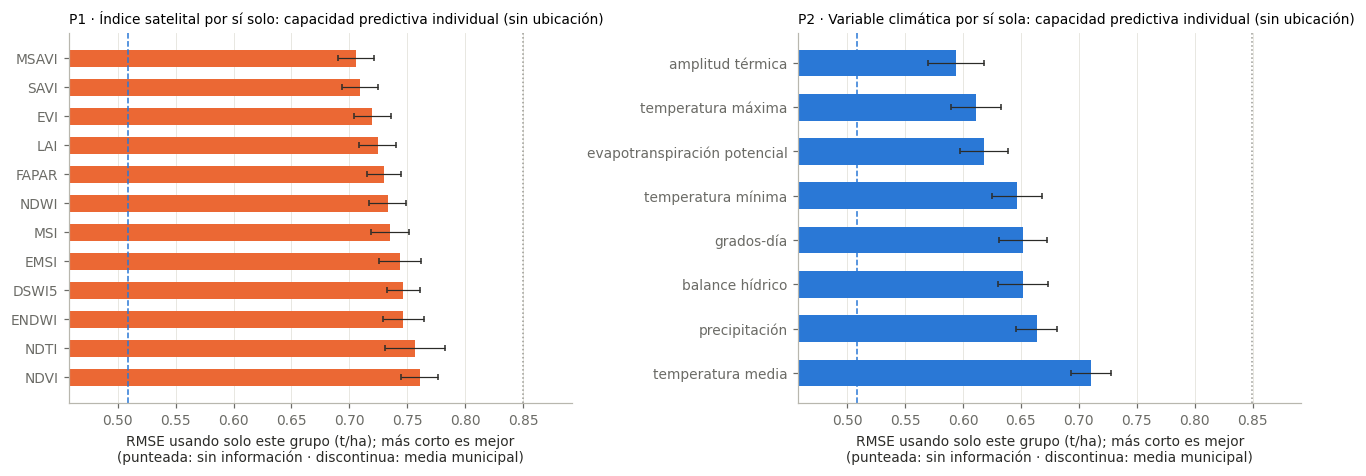

In [9]:
# 4.2 · Enfoque 2: capacidad individual de cada índice satelital (P1) y de cada variable climática (P2)
import re as _re
IDX_NAMES = ["ndvi", "evi", "lai", "msavi", "savi", "fapar", "dswi2", "dswi3", "dswi4", "dswi5", "msi", "emsi", "ndwi", "endwi",
             "nddi", "enddi", "crc", "mcrc", "ndti", "sti", "ndsvi", "srndi", "mra", "vi6t"]
CLIM_VARS = ["prec", "tmax", "tmin", "tmean", "amp", "pet", "wb", "gdd"]
def index_of(f):
    if f.startswith(("clim_", "anom_clim_", "topo_", "soil_")) or f == "area_ha":
        return None
    for p_ in f.split("_"):
        if p_ in IDX_NAMES:
            return p_
    return None
IDX_GROUPS = {k: v for k, v in {i: [f for f in CANDS if index_of(f) == i] for i in IDX_NAMES}.items() if v}
CLIM_GROUPS = {k: v for k, v in {v: [f for f in CANDS if _re.match(rf"^(anom_)?clim_{v}_", f)] for v in CLIM_VARS}.items() if v}

folds_imp = [f for f in FOLDS if f["repeat"] < N_REP_IMPORTANCE]
tr_ids = TR.index.to_numpy()
fold_cache = []
for f in folds_imp:
    te = np.array(f["test"])
    fold_cache.append((TR.loc[np.setdiff1d(tr_ids, te)], TR.loc[te]))

def cv_ridge(cols):
    err = []
    for trn, tst in fold_cache:
        A, B = safe_prep(trn, tst, cols)
        p_ = fit_ridge(A, trn[Y], np.logspace(-1, 5, 30)).predict(B)
        err.append(np.sqrt(np.mean((tst[Y].to_numpy() - p_) ** 2)))
    return np.mean(err), np.std(err, ddof=1) / np.sqrt(len(err))

t0 = time.time()
rows = [{"kind": "index", "group": k, "n_features": len(v), **dict(zip(["rmse", "se"], cv_ridge(v)))} for k, v in IDX_GROUPS.items()] + \
       [{"kind": "climate", "group": k, "n_features": len(v), **dict(zip(["rmse", "se"], cv_ridge(v)))} for k, v in CLIM_GROUPS.items()]
IMP = pd.DataFrame(rows)
no_info = np.mean([np.sqrt(np.mean((tst[Y].to_numpy() - trn[Y].mean()) ** 2)) for trn, tst in fold_cache])
IMP["skill_vs_no_information_%"] = 100 * (1 - IMP.rmse / no_info)
IMP = IMP.sort_values(["kind", "rmse"]).reset_index(drop=True)
print(f"capacidad individual: {len(IMP)} grupos × {len(fold_cache)} pliegues en {time.time() - t0:.0f} s (sin información: RMSE {no_info:.3f})")
display(IMP.round(4))
q1 = IMP[IMP.kind == "index"].iloc[0]; q2 = IMP[IMP.kind == "climate"].iloc[0]
q1b = IMP[IMP.kind == "index"].iloc[1]; q2b = IMP[IMP.kind == "climate"].iloc[1]
check("Pregunta guía 1: índice satelital más importante (capacidad individual, enfoque 2)", True,
      f"{q1.group.upper()}: RMSE {q1.rmse:.3f} ± {q1.se:.3f} por sí solo ({q1['skill_vs_no_information_%']:.0f} % mejor que sin información); "
      f"segundo lugar {q1b.group.upper()} {q1b.rmse:.3f}", info=True)
check("Pregunta guía 2: variable climática de mayor peso (capacidad individual, enfoque 2)", True,
      f"{q2.group}: RMSE {q2.rmse:.3f} ± {q2.se:.3f} por sí sola ({q2['skill_vs_no_information_%']:.0f} % mejor que sin información); "
      f"segundo lugar {q2b.group} {q2b.rmse:.3f}", info=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ref = SCORES.loc["0 municipality mean", "rmse"]
for ax, kind, col, title in [(axes[0], "index", COLORS["satellite"], "P1 · Índice satelital por sí solo"), (axes[1], "climate", COLORS["location"], "P2 · Variable climática por sí sola")]:
    t = IMP[IMP.kind == kind].head(12).iloc[::-1]
    ax.barh(t.group.str.upper() if kind == "index" else t.group.map(lambda g: VAR_CLIMA.get(g, g)), t.rmse, xerr=t.se, color=col, height=0.6,
            error_kw={"ecolor": INK, "lw": 0.8, "capsize": 2})
    ax.axvline(no_info, color=GREY, ls=":", lw=1)
    ax.axvline(ref, color=COLORS["location"], ls="--", lw=1)
    ax.set_xlim(min(t.rmse.min(), ref) * 0.9, no_info * 1.05)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("RMSE usando solo este grupo (t/ha); más corto es mejor\n(punteada: sin información · discontinua: media municipal)")
    ax.set_title(f"{title}: capacidad predictiva individual (sin ubicación)", loc="left", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "nb07_importance_q1_q2.png", bbox_inches="tight"); plt.show()

ablación: 63 combinaciones en 143 s
                                         combination  n_families  n_features    rmse      se
0                                     climate + soil           2          87  0.5379  0.0235
1                                            climate           1          66  0.5397  0.0282
2                           climate + terrain + soil           3          96  0.5484  0.0223
3                                  climate + terrain           2          75  0.5487  0.0240
4       satellite indices + climate + terrain + soil           4         215  0.5525  0.0225
5  satellite indices + history 2022–24 + climate ...           5         223  0.5555  0.0219
6                 satellite indices + climate + soil           3         206  0.5564  0.0233
7  phenology + satellite indices + climate + terr...           5         255  0.5573  0.0215
8              satellite indices + climate + terrain           3         194  0.5576  0.0237
9                        satellite

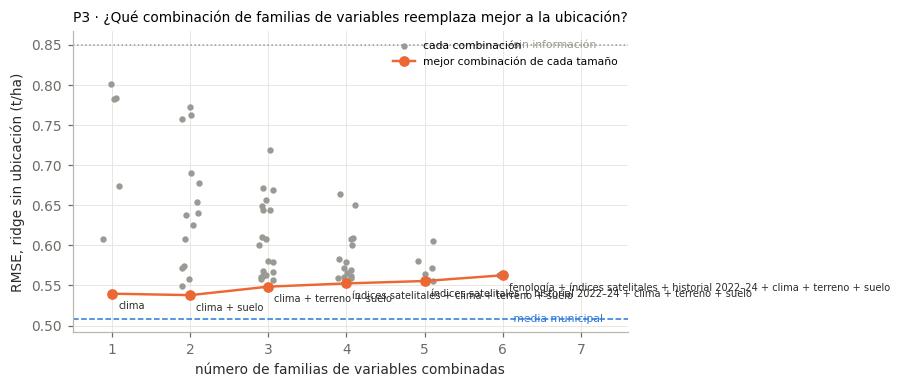

In [10]:
# 4.3 · Enfoque 2: mejor combinación de familias de variables (P3)
FAMILIES = {
    "phenology": [c for c in CANDS if cat.loc[c, "group"] == "phenology"],
    "satellite indices": [c for c in CANDS if cat.loc[c, "group"] in ("window", "uniformity")],
    "history 2022–24": [c for c in CANDS if cat.loc[c, "group"] == "history"],
    "climate": [c for c in CANDS if cat.loc[c, "group"] in ("climate", "climate anomaly")],
    "terrain": [c for c in CANDS if cat.loc[c, "group"] == "terrain"],
    "soil": [c for c in CANDS if cat.loc[c, "group"] == "soil"],
}
FAMILIES = {k: v for k, v in FAMILIES.items() if v}
rows = []
t0 = time.time()
for r_ in range(1, len(FAMILIES) + 1):
    for combo in itertools.combinations(FAMILIES, r_):
        cols = sorted(set(sum((FAMILIES[c] for c in combo), [])))
        m_, se_ = cv_ridge(cols)
        rows.append({"combination": " + ".join(combo), "n_families": r_, "n_features": len(cols), "rmse": m_, "se": se_})
ABL = pd.DataFrame(rows).sort_values("rmse").reset_index(drop=True)
print(f"ablación: {len(ABL)} combinaciones en {time.time() - t0:.0f} s")
display(ABL.head(10).round(4))
single = ABL[ABL.n_families == 1].sort_values("rmse")
display(single.round(4))
best_combo = ABL.iloc[0]
check("Pregunta guía 3: mejor combinación de familias de variables (enfoque 2, ridge sin ubicación)", True,
      f"{best_combo.combination}: RMSE {best_combo.rmse:.3f} ± {best_combo.se:.3f}; mejor familia individual: {single.iloc[0].combination} "
      f"({single.iloc[0].rmse:.3f}); ubicación como referencia: {SCORES.loc['0 municipality mean', 'rmse']:.3f}", info=True)
best_per_n = ABL.loc[ABL.groupby("n_families").rmse.idxmin()].sort_values("n_families")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(ABL.n_families + RNG.uniform(-0.12, 0.12, len(ABL)), ABL.rmse, s=10, color=GREY, label="cada combinación")
ax.plot(best_per_n.n_families, best_per_n.rmse, color=COLORS["satellite"], marker="o", lw=1.6, label="mejor combinación de cada tamaño")
for _, r in best_per_n.iterrows():
    ax.annotate(" + ".join(FAMILIAS.get(f, f) for f in r.combination.split(" + ")), (r.n_families, r.rmse), textcoords="offset points", xytext=(4, -10), fontsize=6.5, color=INK)
ax.axhline(SCORES.loc["0 municipality mean", "rmse"], color=COLORS["location"], ls="--", lw=1)
ax.text(len(FAMILIES) + 0.1, SCORES.loc["0 municipality mean", "rmse"], " media municipal", va="center", fontsize=7, color=COLORS["location"])
ax.axhline(no_info, color=GREY, ls=":", lw=1)
ax.text(len(FAMILIES) + 0.1, no_info, " sin información", va="center", fontsize=7, color=GREY)
ax.set_xlabel("número de familias de variables combinadas"); ax.set_ylabel("RMSE, ridge sin ubicación (t/ha)")
ax.set_title("P3 · ¿Qué combinación de familias de variables reemplaza mejor a la ubicación?", loc="left", fontsize=9)
ax.legend(fontsize=7, loc="upper right"); ax.set_xlim(0.5, len(FAMILIES) + 1.6)
fig.tight_layout(); fig.savefig(FIG / "nb07_ablation_q3.png", bbox_inches="tight"); plt.show()

## 5 · Paso E: ajuste final y predicciones de las 59 parcelas

El modelo elegido se vuelve a ajustar con **las 138 parcelas de entrenamiento** (cada componente exactamente como en la validación cruzada, incluida la selección de variables) y se aplica a las 59 parcelas de predicción. Luego los multiplicadores conformes dan P10/P20/P80/P90 y el nivel de riesgo. También se reajusta el bosque aleatorio solo satelital, para que la aplicación muestre qué predeciría la percepción remota por sí sola.

**Verificaciones antes de exportar:** exactamente las 59 parcelas PREDICCION, sin valores faltantes, predicciones dentro del rango de rendimientos observados e intervalos ordenados (P10 ≤ P20 ≤ predicción ≤ P80 ≤ P90).

In [11]:
# 5.1 · Reajuste y predicción
def fit_component(name, tr, te):
    if name == "0 municipality mean":
        return muni_prior(tr.Municipio, tr[Y], te.Municipio)[1], None
    if name == "5 hierarchical GP":
        h = HierGP(use_features=False, restarts=3, seed=SEED).fit(tr[XY].to_numpy(), tr.Municipio, np.zeros((len(tr), 0)), tr[Y])
        mean, sd = h.predict(te[XY].to_numpy(), te.Municipio, np.zeros((len(te), 0)), return_std=True)
        fit_component.hgp = h
        return mean, sd
    if name == "6 hierarchical GP + features":
        ranked = select_features(tr, tr[Y], tr.Municipio, CANDS, CLUSTERS, 10)
        best = None
        for k in [0, 3, 6, 10]:
            A, B = prep(tr, te, ranked[:k])
            h = HierGP(use_features=k > 0, restarts=3, seed=SEED).fit(tr[XY].to_numpy(), tr.Municipio, A, tr[Y])
            if best is None or h.nll < best[0].nll:
                best = (h, B, ranked[:k])
        fit_component.hgpf_features = best[2]
        return best[0].predict(te[XY].to_numpy(), te.Municipio, best[1], return_std=True)
    if name == "8 satellite-only ridge":
        return sat_ridge(tr, te), None
    if name == "9 satellite-only random forest":
        return sat_rf(tr, te), None
    raise ValueError(name)

comp_pred = {}
hgp_mean, hgp_sd = fit_component("5 hierarchical GP", TR, PR)
comp_pred["5 hierarchical GP"] = hgp_mean
if FINAL == "stack":
    for i, name in enumerate(CANDIDATES):
        if W_FULL[i] > 0 and name not in comp_pred:
            comp_pred[name] = fit_component(name, TR, PR)[0]
    pred = sum(W_FULL[i] * comp_pred[n] for i, n in enumerate(CANDIDATES) if W_FULL[i] > 0)
    sd_final = hgp_sd
else:
    if FINAL not in comp_pred:
        comp_pred[FINAL], sd_tmp = fit_component(FINAL, TR, PR)
    pred = comp_pred[FINAL]
    sd_final = hgp_sd
sat_pred = sat_rf(TR, PR)

final = pd.DataFrame({"ID_POLIGONO": PR.index, "Municipio": PR.Municipio.values, "Estado": PR.Estado.values,
                      "RENDIMIENTO_PRED_T_HA": pred, "sd": sd_final}).set_index("ID_POLIGONO")
for k in LEVELS:
    final[k] = final.RENDIMIENTO_PRED_T_HA + Q[k] * final.sd
down = (final.RENDIMIENTO_PRED_T_HA - final.P20) / final.RENDIMIENTO_PRED_T_HA
t1, t2 = down.quantile([1 / 3, 2 / 3])
final["riesgo"] = np.where(down <= t1, "Bajo", np.where(down <= t2, "Medio", "Alto"))
final["RENDIMIENTO_SATELITAL_T_HA"] = sat_pred
dist = np.sqrt(((PR[XY].to_numpy()[:, None] - TR[XY].to_numpy()[None]) ** 2).sum(-1)).min(1)
final["dist_parcela_entrenamiento_km"] = dist

lo, hi = TR[Y].min(), TR[Y].max()
checks_ok = {
    "exactamente las 59 parcelas PREDICCION": len(final) == 59 and set(final.index) == set(PR.index),
    "sin valores faltantes": bool(final[["RENDIMIENTO_PRED_T_HA", "P10", "P20", "P80", "P90"]].notna().all().all()),
    f"predicciones dentro del rango observado {lo:.2f}–{hi:.2f} t/ha": bool(final.RENDIMIENTO_PRED_T_HA.between(lo, hi).all()),
    "intervalos ordenados": bool(((final.P10 <= final.P20) & (final.P20 <= final.RENDIMIENTO_PRED_T_HA) &
                               (final.RENDIMIENTO_PRED_T_HA <= final.P80) & (final.P80 <= final.P90)).all()),
}
for k, v in checks_ok.items():
    check(f"Predicciones finales: {k}", v, warn_only=False)
display(final.round(3).head(10))
display(final.groupby("Municipio").agg(plots=("P20", "size"), pred_mean=("RENDIMIENTO_PRED_T_HA", "mean"),
                                       p20_mean=("P20", "mean"), alto=("riesgo", lambda s: (s == "Alto").sum())).round(2))

[PASS] Predicciones finales: exactamente las 59 parcelas PREDICCION
[PASS] Predicciones finales: sin valores faltantes
[PASS] Predicciones finales: predicciones dentro del rango observado 2.00–5.59 t/ha
[PASS] Predicciones finales: intervalos ordenados
                Municipio    Estado  RENDIMIENTO_PRED_T_HA     sd    P10    P20    P80    P90 riesgo  RENDIMIENTO_SATELITAL_T_HA  dist_parcela_entrenamiento_km
ID_POLIGONO                                                                                                                                                    
AGC_003       Singuilucan   Hidalgo                  3.293  0.496  2.722  2.894  3.673  3.853   Alto                       3.436                          0.381
AGC_011      Chignahuapan    Puebla                  4.508  0.507  3.925  4.101  4.896  5.080  Medio                       4.682                          0.833
AGC_016      Chignahuapan    Puebla                  4.577  0.418  4.096  4.241  4.898  5.049   Bajo       

In [12]:
# 5.2 · Exportación: archivo de entrega, archivo de todas las parcelas y paquete de la aplicación
sub = final[["Municipio", "Estado", "RENDIMIENTO_PRED_T_HA", "P10", "P20", "P80", "P90", "riesgo",
             "RENDIMIENTO_SATELITAL_T_HA", "dist_parcela_entrenamiento_km"]].round(3).reset_index()
sub.to_csv(OUT / "predicciones_finales.csv", index=False, encoding="utf-8")

oof_mean = oof_final.groupby("ID_POLIGONO")[["pred", "sd"]].mean()
train_rows = pd.DataFrame({"ID_POLIGONO": TR.index, "Municipio": TR.Municipio.values, "Estado": TR.Estado.values,
                           "CONJUNTO": "ENTRENAMIENTO", "RENDIMIENTO_OBS_T_HA": TR[Y].values,
                           "RENDIMIENTO_PRED_T_HA": oof_mean.reindex(TR.index).pred.values,
                           "sd": oof_mean.reindex(TR.index).sd.values}).set_index("ID_POLIGONO")
for k in LEVELS:
    train_rows[k] = train_rows.RENDIMIENTO_PRED_T_HA + Q[k] * train_rows.sd
allp = pd.concat([train_rows, final.assign(CONJUNTO="PREDICCION")], sort=False)
allp = allp.join(MASTER[["lon", "lat"]])
allp.round(4).reset_index().to_csv(OUT / "predicciones_todas.csv", index=False, encoding="utf-8")

h = fit_component.hgp
bundle = {"final_model": FINAL, "ensemble_weights": dict(zip(CANDIDATES, np.round(W_FULL, 4).tolist())),
          "conformal_quantiles": Q, "risk_thresholds_relative_downside": [float(t1), float(t2)],
          "hgp_params": {k: float(v) for k, v in h.params().items()}, "hgp_raw_params": h.p.tolist(),
          "oof_rmse_final": float(rm), "baseline_rmse": float(SCORES.loc["0 municipality mean", "rmse"]),
          "created": datetime.now().isoformat(timespec="seconds")}
(APP / "model_bundle.json").write_text(json.dumps(bundle, indent=1))
TR[["Municipio", "x_km", "y_km", Y]].reset_index().to_csv(APP / "training_plots.csv", index=False)
IMP.to_csv(APP / "standalone_skill_q1_q2.csv", index=False)
ABL.to_csv(APP / "ablation_q3.csv", index=False)
PERM.reset_index().to_csv(APP / "permutation_test_lens1.csv", index=False)
pd.concat([SCORES.assign(scheme="main"), SCORES_SP.assign(scheme="spatial")]).round(4).reset_index().to_csv(APP / "model_scores.csv", index=False)
print("guardado:", OUT / "predicciones_finales.csv", "|", OUT / "predicciones_todas.csv", "|", APP)

guardado: /content/drive/MyDrive/AgroCebada/outputs/predicciones_finales.csv | /content/drive/MyDrive/AgroCebada/outputs/predicciones_todas.csv | /content/drive/MyDrive/AgroCebada/outputs/app_bundle


In [13]:
# 5.3 · Reproducibilidad: comparar con las predicciones entregadas al reto
# outputs/referencia/predicciones_finales_entregadas.csv es una copia de la tabla del Anexo del reporte.
REF = OUT / "referencia" / "predicciones_finales_entregadas.csv"
if REF.exists():
    ref = pd.read_csv(REF).set_index("ID_POLIGONO").RENDIMIENTO_PRED_T_HA
    nueva = sub.set_index("ID_POLIGONO").RENDIMIENTO_PRED_T_HA
    dif = (nueva - ref.reindex(nueva.index)).abs()
    check("Las predicciones reproducen las entregadas al reto (diferencia máxima < 0.01 t/ha)",
          bool(set(ref.index) == set(nueva.index) and dif.max() < 0.01),
          f"diferencia máxima {dif.max():.4f} t/ha; diferencia media {dif.mean():.4f} t/ha")
else:
    print(f"No se encontró {REF}; se omite la comparación.")


No se encontró /content/drive/MyDrive/AgroCebada/outputs/referencia/predicciones_finales_entregadas.csv; se omite la comparación.


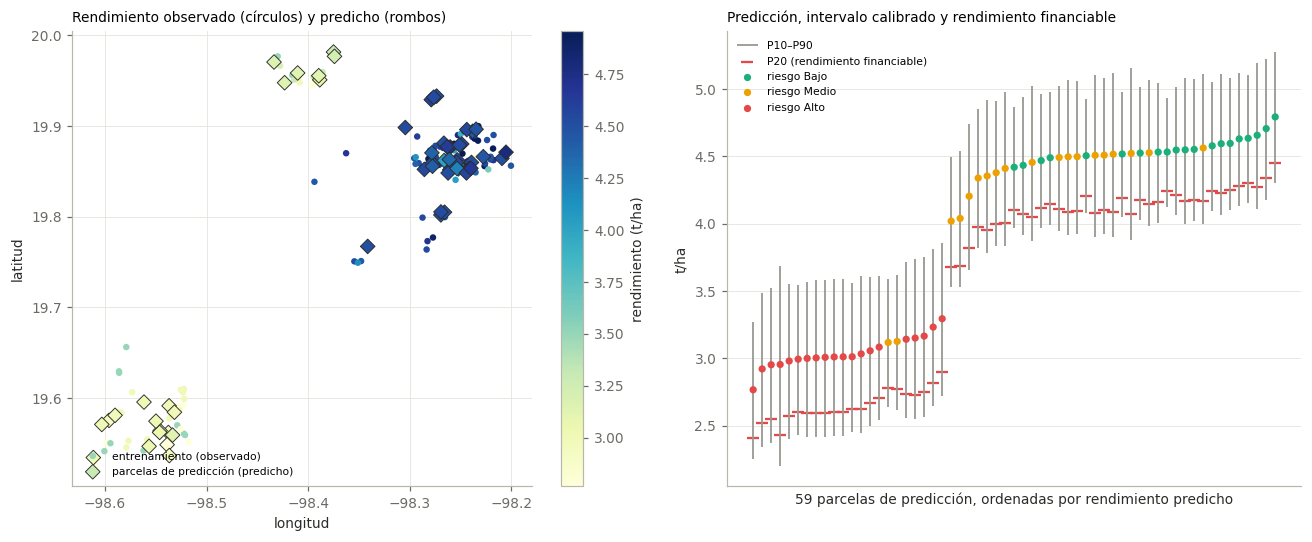

In [14]:
# 5.4 · Figura: dónde están las predicciones y qué tan seguras son
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ax = axes[0]
trp = allp[allp.CONJUNTO == "ENTRENAMIENTO"]; prp = allp[allp.CONJUNTO == "PREDICCION"]
vmin, vmax = allp.RENDIMIENTO_PRED_T_HA.min(), allp.RENDIMIENTO_PRED_T_HA.max()
sc = ax.scatter(trp.lon, trp.lat, c=trp.RENDIMIENTO_OBS_T_HA, cmap="YlGnBu", vmin=vmin, vmax=vmax, s=18, marker="o", edgecolors="none", label="entrenamiento (observado)")
ax.scatter(prp.lon, prp.lat, c=prp.RENDIMIENTO_PRED_T_HA, cmap="YlGnBu", vmin=vmin, vmax=vmax, s=46, marker="D", edgecolors=INK, linewidths=0.6, label="parcelas de predicción (predicho)")
plt.colorbar(sc, ax=ax, label="rendimiento (t/ha)")
ax.set_xlabel("longitud"); ax.set_ylabel("latitud"); ax.legend(fontsize=7, loc="lower left")
ax.set_title("Rendimiento observado (círculos) y predicho (rombos)", loc="left", fontsize=9)
ax = axes[1]
o = final.sort_values("RENDIMIENTO_PRED_T_HA")
x = np.arange(len(o))
ax.vlines(x, o.P10, o.P90, color=GREY, lw=1.2, label="P10–P90")
ax.scatter(x, o.P20, marker="_", s=60, color=RED, label="P20 (rendimiento financiable)")
ax.scatter(x, o.RENDIMIENTO_PRED_T_HA, s=14, c=[TIER_COLORS[t] for t in o.riesgo], zorder=3)
for t, c in TIER_COLORS.items():
    ax.scatter([], [], s=14, color=c, label=f"riesgo {t}")
ax.set_xticks([]); ax.set_xlabel("59 parcelas de predicción, ordenadas por rendimiento predicho"); ax.set_ylabel("t/ha")
ax.set_title("Predicción, intervalo calibrado y rendimiento financiable", loc="left", fontsize=9); ax.legend(fontsize=7, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "nb07_predictions.png", bbox_inches="tight"); plt.show()

In [15]:
# 5.5 · Reporte
def md_table(df):
    df = df.copy()
    cols = [str(c) for c in df.columns]
    out = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for _, r in df.iterrows():
        out.append("| " + " | ".join("" if pd.isna(v) else (f"{v:.4g}" if isinstance(v, float) else str(v)) for v in r.values) + " |")
    return "\n".join(out)

chk = pd.DataFrame(CHECKS)
lines = ["# Reporte del cuaderno 07: ensamble, intervalos, preguntas guía y predicciones finales",
         f"Generado {datetime.now():%Y-%m-%d %H:%M} · Colab: {IN_COLAB} · modelo final: **{FINAL}** · RMSE fuera de pliegue {rm:.4f} t/ha", "",
         f"**Conteo de estados:** {chk.status.value_counts().to_dict()}", "",
         "## Verificaciones", md_table(chk), "",
         "## Métricas de los modelos: pliegues principales", md_table(SCORES.round(4).reset_index()), "",
         "## Métricas de los modelos: bloques espaciales (zonas nuevas)", md_table(SCORES_SP.round(4).reset_index()), "",
         "## Pesos del ensamble", md_table(wt.round(3).reset_index().rename(columns={"index": "model"})), "",
         "## Cuantiles conformes y cobertura validada", md_table(pd.Series(Q, name="quantile").round(3).reset_index()), "", md_table(cov_tab.round(3).reset_index()), "",
         "## Enfoque 1: señal dentro de municipio frente al azar (prueba de permutación)", md_table(PERM.round(3).reset_index()), "",
         "## Enfoque 2: P1/P2, capacidad individual de cada índice y variable climática (ridge, sin ubicación)", md_table(IMP.round(4)), "",
         "## Enfoque 2: P3, mejores combinaciones (ridge sin ubicación, 10 primeras)", md_table(ABL.head(10).round(4)), "",
         "## Enfoque 2: familias individuales", md_table(single.round(4)), "",
         "## Predicciones por municipio", md_table(final.groupby("Municipio").agg(plots=("P20", "size"), pred_mean=("RENDIMIENTO_PRED_T_HA", "mean"), p20_mean=("P20", "mean")).round(3).reset_index())]
(QA / "nb07_report.md").write_text("\n".join(lines), encoding="utf-8")
print(chk.status.value_counts().to_dict())
problems = chk[chk.status.isin(["WARN", "FAIL"])]
display(problems if len(problems) else "Todas las verificaciones pasaron.")
print(f"Reporte: {QA / 'nb07_report.md'}")

{'INFO': 8, 'PASS': 5, 'WARN': 1}
                                               check status                                             detail
2  Ensamble apilado frente al mejor modelo indivi...   WARN  mejor individual: 5 hierarchical GP; Δ RMSE de...
Reporte: /content/drive/MyDrive/AgroCebada/qa/nb07_report.md


## Resultado

1. **`outputs/predicciones_finales.csv`**: la entrega, una fila por parcela de predicción. El valor evaluado es `RENDIMIENTO_PRED_T_HA`.
2. **`qa/figures/nb07_stack_weights.png`**: qué modelos pusieron los datos en el ensamble.
3. **`qa/figures/nb07_importance_q1_q2.png`** y **`nb07_ablation_q3.png`**: la evidencia de las tres preguntas guía.
4. **`qa/figures/nb07_predictions.png`**: el mapa y los intervalos calibrados.
5. **`qa/nb07_report.md`**: todas las métricas y verificaciones. La aplicación web lee `outputs/predicciones_todas.csv` y `outputs/app_bundle/`.